# 02 — Exploratory Data Analysis

Goal: understand the salary target, how salary relates to performance, and which structural factors (age, contract
type, position, team) need to be handled before modeling.

In [1]:
import sys
sys.path.append("../src")
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features import build_features
import plotting as P

P.setup()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.0f}" if abs(x) >= 1000 else f"{x:,.3f}")

In [2]:
df = build_features(pd.read_csv("../data/processed/player_seasons.csv"))
paid = df[df.has_salary].copy()
print(f"All player-seasons: {len(df):,} | with salary: {len(paid):,} | modeling sample (salary & >=250 min): {df.modeling_sample.sum():,}")

All player-seasons: 5,968 | with salary: 5,419 | modeling sample (salary & >=250 min): 4,488


## 1. Data quality and coverage

In [3]:
coverage = df.groupby("season").agg(players=("player_id", "size"),
                                    with_salary=("has_salary", "sum"),
                                    modeling_sample=("modeling_sample", "sum"))
coverage["salary_match_rate"] = coverage.with_salary / coverage.players
coverage

,players,with_salary,modeling_sample,salary_match_rate
season,,,,
2016,476,476,400,1.000
2017,486,484,397,0.996
2018,540,483,391,0.894
2019,530,482,405,0.909
2020,529,480,401,0.907
2021,540,481,402,0.891
2022,605,562,424,0.929
2023,539,485,407,0.900
2024,572,499,415,0.872


In [4]:
key_cols = ["salary", "age", "pos", "g", "mp_per_g", "pts", "ts_pct", "ws", "bpm", "vorp", "per",
            "height_in", "weight", "years_experience", "pick_overall", "team_win_pct",
            "prev_ws", "prev_vorp"]
missing = (df[key_cols].isna().mean().rename("all_rows").to_frame()
           .join(df.loc[df.modeling_sample == 1, key_cols].isna().mean().rename("modeling_sample")))
missing.sort_values("all_rows", ascending=False).style.format("{:.1%}")

,all_rows,modeling_sample
prev_vorp,28.5%,20.4%
prev_ws,28.5%,20.4%
pick_overall,24.7%,15.4%
salary,9.2%,0.0%
mp_per_g,0.0%,0.0%
pts,0.0%,0.0%
ts_pct,0.0%,0.0%
ws,0.0%,0.0%
bpm,0.0%,0.0%
age,0.0%,0.0%


*Missingness notes:* `pick_overall` is missing by design for undrafted players (captured by the `undrafted` flag).
`prev_*` features are missing for a player's first season in the data (rookies, players returning from a gap, and
everyone in 2015-16 since we start there). Stats themselves are essentially complete; shooting percentages are
missing only when a player took zero attempts of that type.

In [5]:
sal_raw = pd.read_csv("../data/raw/salaries.csv")
paid_no_stats = (sal_raw.groupby(["season", "player_id"]).salary.max().reset_index()
                 .merge(df[["season", "player_id"]], how="left", indicator=True)
                 .query("_merge == 'left_only'"))
print(f"Salary records with no stats line that season: {len(paid_no_stats):,} "
      f"(players paid but who never played — season-long injuries, waived contracts)")
print("Top 8 by salary:")
(paid_no_stats.merge(sal_raw[["season", "player_id", "player"]].drop_duplicates(["season", "player_id"]))
    .nlargest(8, "salary")[["season", "player", "salary"]]
    .style.format({"salary": "${:,.0f}"}).hide(axis="index"))

Salary records with no stats line that season: 551 (players paid but who never played — season-long injuries, waived contracts)
Top 8 by salary:


season,player,salary
2026,Tyrese Haliburton,"$45,550,512"
2022,John Wall,"$44,310,840"
2022,Kawhi Leonard,"$39,344,900"
2020,John Wall,"$38,199,000"
2020,Kevin Durant,"$37,199,000"
2026,Kyrie Irving,"$36,566,002"
2021,Klay Thompson,"$35,361,360"
2022,Ben Simmons,"$33,003,936"


## 2. The target: salary

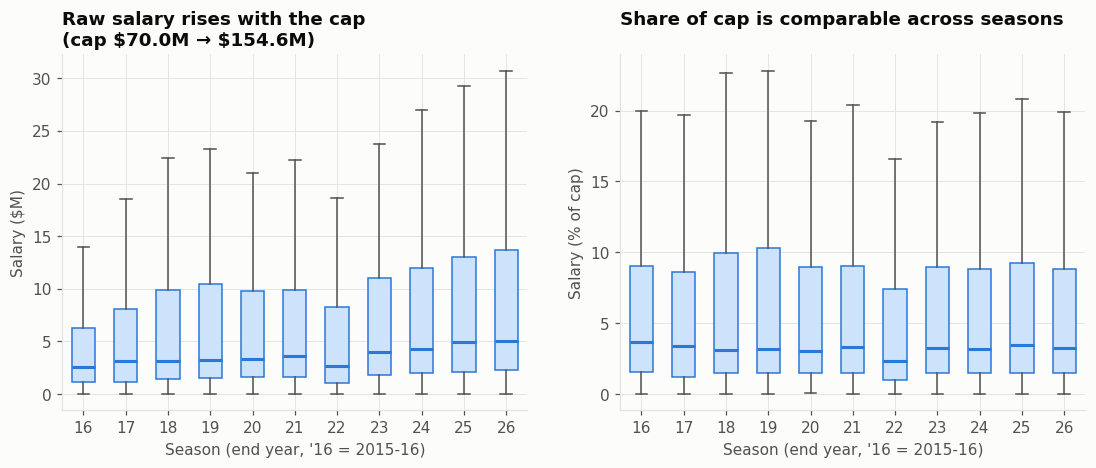

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
seasons = sorted(paid.season.unique())
cap = paid.groupby("season").salary_cap.first() / 1e6
data_m = [paid.loc[paid.season == s, "salary"] / 1e6 for s in seasons]
data_p = [paid.loc[paid.season == s, "salary_pct_cap"] * 100 for s in seasons]
raw_title = f"Raw salary rises with the cap\n(cap \\${cap.iloc[0]:.1f}M → \\${cap.iloc[-1]:.1f}M)"
for ax, data, title, ylab in [(axes[0], data_m, raw_title, "Salary ($M)"),
                              (axes[1], data_p, "Share of cap is comparable across seasons\n", "Salary (% of cap)")]:
    ax.boxplot(data, labels=[str(s)[2:] for s in seasons], showfliers=False, widths=0.55,
               patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=P.BLUE),
               medianprops=dict(color=P.BLUE, linewidth=2), whiskerprops=dict(color=P.TEXT_2),
               capprops=dict(color=P.TEXT_2))
    ax.set_title(title); ax.set_ylabel(ylab); ax.set_xlabel("Season (end year, '16 = 2015-16)")
P.save(fig, "eda_salary_by_season")
plt.show()

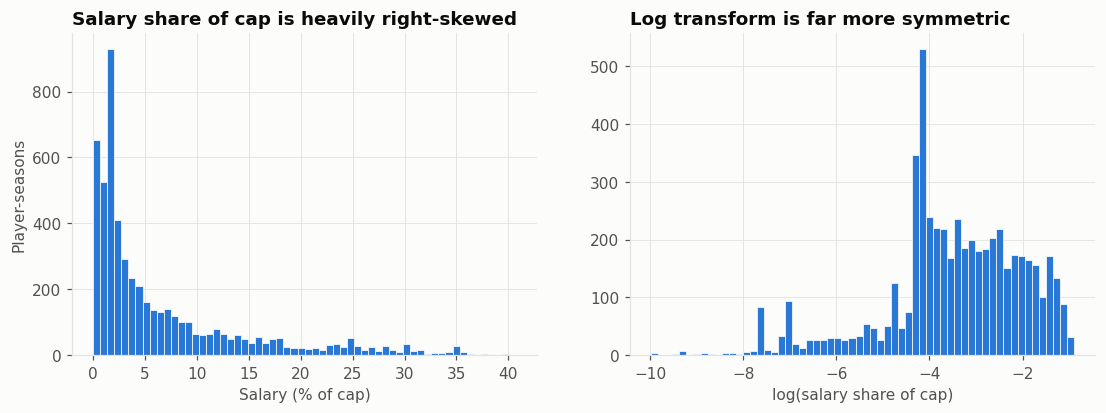

skew(salary_pct_cap) = 1.75 | skew(log) = -0.84


,salary_pct_cap
count,"5,419"
mean,0.067
std,0.081
min,0.000
10%,0.005
25%,0.015
50%,0.032
75%,0.089
90%,0.187
99%,0.347


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(paid.salary_pct_cap * 100, bins=60, color=P.BLUE, edgecolor=P.SURFACE, linewidth=0.5)
axes[0].set_title("Salary share of cap is heavily right-skewed"); axes[0].set_xlabel("Salary (% of cap)"); axes[0].set_ylabel("Player-seasons")
axes[1].hist(np.log(paid.salary_pct_cap), bins=60, color=P.BLUE, edgecolor=P.SURFACE, linewidth=0.5)
axes[1].set_title("Log transform is far more symmetric"); axes[1].set_xlabel("log(salary share of cap)")
P.save(fig, "eda_target_distribution")
plt.show()
print(f"skew(salary_pct_cap) = {paid.salary_pct_cap.skew():.2f} | skew(log) = {np.log(paid.salary_pct_cap).skew():.2f}")
paid.salary_pct_cap.describe(percentiles=[.1, .25, .5, .75, .9, .99]).to_frame("salary_pct_cap")

In [8]:
def top_share(s, q=0.9):
    return s[s >= s.quantile(q)].sum() / s.sum()

conc = paid.groupby("season").agg(
    top10_share=("salary", top_share),
    max_tier_players=("salary_pct_cap", lambda s: (s >= 0.25).sum()),
    median_pct_cap=("salary_pct_cap", "median"))
conc

,top10_share,max_tier_players,median_pct_cap
season,,,
2016,0.373,17,0.037
2017,0.360,10,0.034
2018,0.370,16,0.031
2019,0.380,21,0.032
2020,0.394,29,0.031
2021,0.410,41,0.033
2022,0.452,34,0.023
2023,0.407,38,0.032
2024,0.402,31,0.032


## 3. Does pay track performance?

In [9]:
vets = df[(df.modeling_sample == 1) & (df.has_prev_season == 1)]
metrics = ["vorp", "ws", "bpm", "per", "pts", "mp_total", "usg_pct", "ts_pct", "ast", "trb", "availability"]
corr = pd.DataFrame({
    "same season": [vets[m].corr(vets.salary_pct_cap, method="spearman") for m in metrics],
    "previous season": [vets[f"prev_{m}"].corr(vets.salary_pct_cap, method="spearman") for m in metrics],
}, index=metrics).sort_values("previous season")
print(f"Players with a salary, >=250 min and a previous season: n = {len(vets):,}")
corr.sort_values("previous season", ascending=False)

Players with a salary, >=250 min and a previous season: n = 3,574


,same season,previous season
pts,0.615,0.700
mp_total,0.498,0.612
ws,0.465,0.604
vorp,0.489,0.594
ast,0.483,0.533
trb,0.449,0.525
bpm,0.434,0.499
per,0.407,0.447
usg_pct,0.401,0.396
availability,0.180,0.321


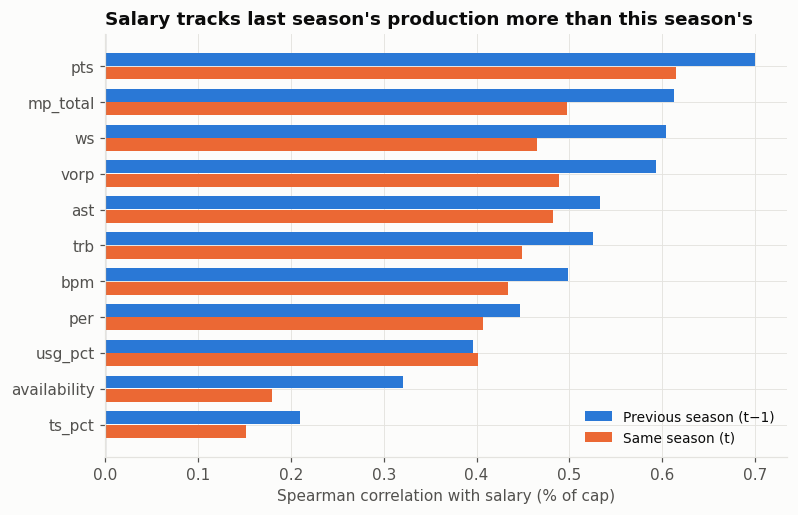

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(corr))
ax.barh(y + 0.19, corr["previous season"], height=0.36, color=P.BLUE, label="Previous season (t−1)")
ax.barh(y - 0.19, corr["same season"], height=0.36, color=P.ORANGE, label="Same season (t)")
ax.set_yticks(y, corr.index); ax.axvline(0, color=P.TEXT_2, linewidth=0.8)
ax.set_xlabel("Spearman correlation with salary (% of cap)")
ax.set_title("Salary tracks last season's production more than this season's")
ax.legend(loc="lower right")
P.save(fig, "eda_corr_current_vs_prev")
plt.show()

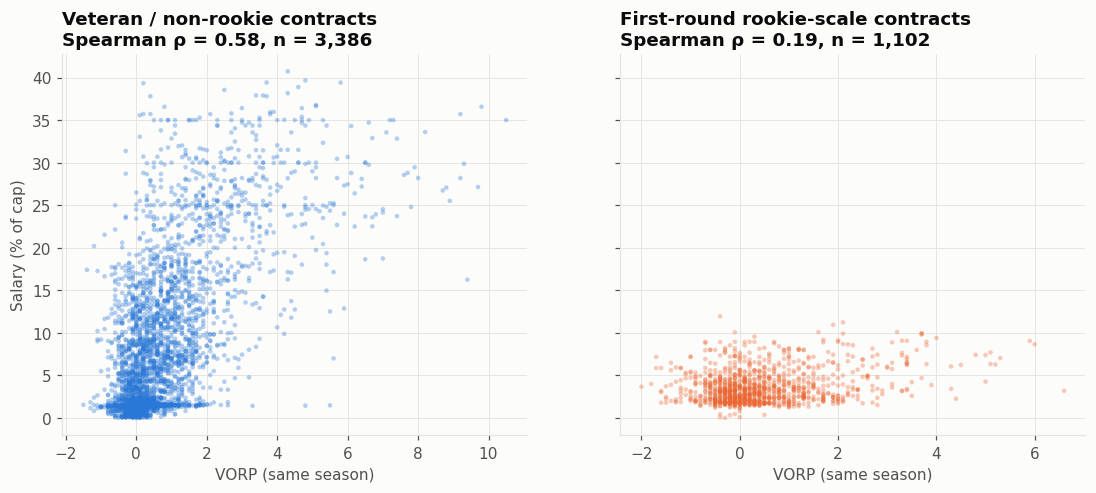

In [11]:
mp = df[df.modeling_sample == 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (flag, label, color) in zip(axes, [(0, "Veteran / non-rookie contracts", P.BLUE), (1, "First-round rookie-scale contracts", P.ORANGE)]):
    sub = mp[mp.rookie_scale == flag]
    ax.scatter(sub.vorp, sub.salary_pct_cap * 100, s=9, alpha=0.35, color=color, edgecolors="none")
    rho = sub.vorp.corr(sub.salary_pct_cap, method="spearman")
    ax.set_title(f"{label}\nSpearman ρ = {rho:.2f}, n = {len(sub):,}")
    ax.set_xlabel("VORP (same season)")
axes[0].set_ylabel("Salary (% of cap)")
P.save(fig, "eda_vorp_vs_salary_by_contract")
plt.show()

## 4. Age, experience and contract structure

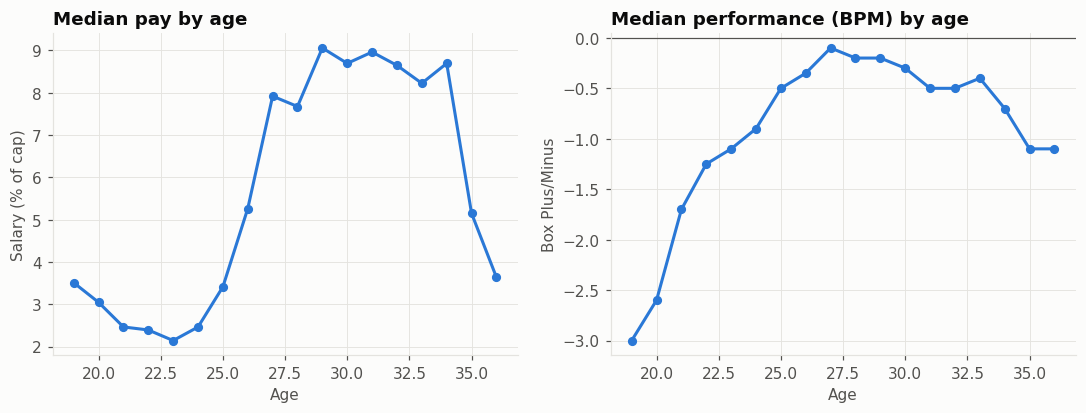

,n,median_pct_cap,median_bpm,median_vorp
age,,,,
19,91,0.035,-3.000,-0.200
20,206,0.030,-2.600,-0.100
21,289,0.025,-1.700,0.100
22,354,0.024,-1.250,0.200
23,411,0.021,-1.100,0.300
24,430,0.025,-0.900,0.300
25,399,0.034,-0.500,0.400
26,366,0.053,-0.350,0.600
27,343,0.079,-0.100,0.600


In [12]:
age_tbl = (mp[(mp.age >= 19) & (mp.age <= 36)].groupby("age")
           .agg(n=("player_id", "size"), median_pct_cap=("salary_pct_cap", "median"), median_bpm=("bpm_raw", "median"),
                median_vorp=("vorp", "median")))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
axes[0].plot(age_tbl.index, age_tbl.median_pct_cap * 100, color=P.BLUE, marker="o", markersize=5)
axes[0].set_title("Median pay by age"); axes[0].set_ylabel("Salary (% of cap)"); axes[0].set_xlabel("Age")
axes[1].plot(age_tbl.index, age_tbl.median_bpm, color=P.BLUE, marker="o", markersize=5)
axes[1].axhline(0, color=P.TEXT_2, linewidth=0.8)
axes[1].set_title("Median performance (BPM) by age"); axes[1].set_ylabel("Box Plus/Minus"); axes[1].set_xlabel("Age")
P.save(fig, "eda_age_curves")
plt.show()
age_tbl

In [13]:
def stage(r):
    if r.rookie_scale == 1:
        return "1. Rookie scale (1st rd, ≤3 yrs)"
    if r.years_experience <= 3:
        return "2. Early career (2nd rd/undrafted)"
    if r.years_experience <= 9:
        return "3. Veteran (4–9 yrs)"
    return "4. Veteran (10+ yrs)"

mp = mp.assign(career_stage=mp.apply(stage, axis=1), pos_vorp=mp.vorp.clip(lower=0))
stage_tbl = mp.groupby("career_stage").agg(n=("player_id", "size"),
                                           median_pct_cap=("salary_pct_cap", "median"),
                                           median_vorp=("vorp", "median"),
                                           median_bpm=("bpm_raw", "median"),
                                           total_pct_cap=("salary_pct_cap", "sum"),
                                           total_pos_vorp=("pos_vorp", "sum"))
# Cap share paid per unit of (positive) VORP: lower = cheaper production.
stage_tbl["pct_cap_per_vorp"] = stage_tbl.total_pct_cap / stage_tbl.total_pos_vorp
stage_tbl.drop(columns=["total_pct_cap", "total_pos_vorp"])

,n,median_pct_cap,median_vorp,median_bpm,pct_cap_per_vorp
career_stage,,,,,
"1. Rookie scale (1st rd, ≤3 yrs)",1102,0.032,0.200,-1.300,0.057
2. Early career (2nd rd/undrafted),956,0.014,0.100,-1.700,0.064
3. Veteran (4–9 yrs),1757,0.098,0.700,-0.100,0.102
4. Veteran (10+ yrs),673,0.089,0.500,-0.300,0.120


## 5. Position

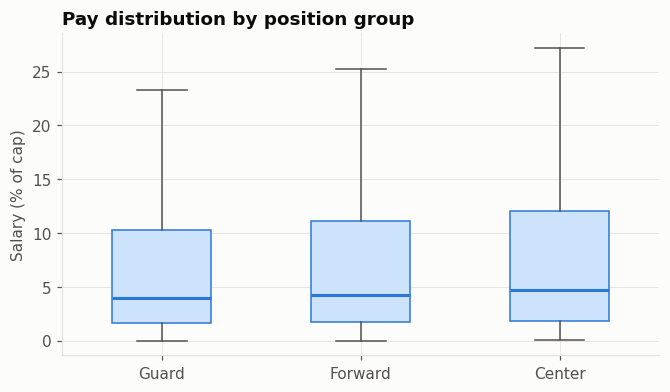

,salary_pct_cap,pts,trb,ast,bpm_raw,vorp,height_in
pos_group,,,,,,,
Guard,0.040,9.400,2.800,2.600,-1.100,0.300,76.000
Forward,0.043,8.600,4.000,1.400,-1.000,0.300,80.000
Center,0.047,8.100,5.600,1.200,0.300,0.600,83.000


In [14]:
pos_order = ["Guard", "Forward", "Center"]
fig, ax = plt.subplots(figsize=(7, 3.8))
data = [mp.loc[mp.pos_group == p, "salary_pct_cap"] * 100 for p in pos_order]
ax.boxplot(data, labels=pos_order, showfliers=False, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=P.BLUE), medianprops=dict(color=P.BLUE, linewidth=2),
           whiskerprops=dict(color=P.TEXT_2), capprops=dict(color=P.TEXT_2))
ax.set_ylabel("Salary (% of cap)"); ax.set_title("Pay distribution by position group")
P.save(fig, "eda_salary_by_position")
plt.show()
mp.groupby("pos_group")[["salary_pct_cap", "pts", "trb", "ast", "bpm_raw", "vorp", "height_in"]].median().loc[pos_order]

## 6. Team level: does spending buy wins?

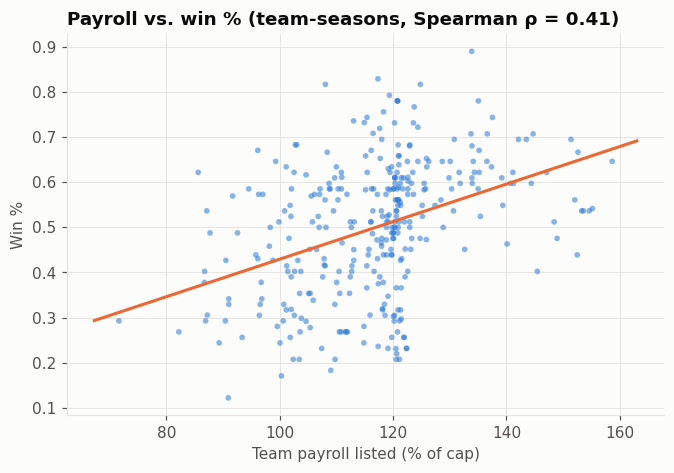

330 team-seasons


In [15]:
teams = pd.read_csv("../data/raw/teams.csv")
cap = pd.read_csv("../data/raw/salary_cap.csv")[["season", "salary_cap"]]
payroll = (sal_raw.groupby(["season", "team"]).salary.sum().reset_index()
           .merge(cap, on="season").merge(teams, on=["season", "team"]))
payroll["payroll_pct_cap"] = payroll.salary / payroll.salary_cap
payroll["win_pct"] = payroll.wins / (payroll.wins + payroll.losses)
rho = payroll.payroll_pct_cap.corr(payroll.win_pct, method="spearman")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(payroll.payroll_pct_cap * 100, payroll.win_pct, s=14, alpha=0.55, color=P.BLUE, edgecolors="none")
b = np.polyfit(payroll.payroll_pct_cap * 100, payroll.win_pct, 1)
xs = np.linspace(*ax.get_xlim(), 50); ax.plot(xs, np.polyval(b, xs), color=P.ORANGE, linewidth=2)
ax.set_xlabel("Team payroll listed (% of cap)"); ax.set_ylabel("Win %")
ax.set_title(f"Payroll vs. win % (team-seasons, Spearman ρ = {rho:.2f})")
P.save(fig, "eda_payroll_vs_wins")
plt.show()
print(f"{len(payroll)} team-seasons")

*Caveat:* team-page salary tables list every player who appeared for the team, so traded players are counted on
both teams. This inflates listed payroll above the cap for some teams; it is fine for a first look but the final
team-level analysis will pro-rate salaries by games played with each team.

## 7. Outliers worth knowing about

In [16]:
print("Highest-paid player-seasons with < 250 minutes (injuries / dead money), excluded from the modeling sample:")
(paid[paid.mp_total < 250].nlargest(8, "salary")[["season", "player", "salary", "salary_pct_cap", "g", "mp_total"]]
    .style.format({"salary": "${:,.0f}", "salary_pct_cap": "{:.1%}", "g": "{:.0f}", "mp_total": "{:.0f}"})
    .hide(axis="index"))

Highest-paid player-seasons with < 250 minutes (injuries / dead money), excluded from the modeling sample:


season,player,salary,salary_pct_cap,g,mp_total
2020,Stephen Curry,"$40,231,758",36.9%,5,139
2018,Gordon Hayward,"$29,727,900",30.0%,1,5
2020,Chandler Parsons,"$25,102,511",23.0%,5,54
2024,Joe Harris,"$19,928,571",14.7%,16,170
2018,Kawhi Leonard,"$18,868,625",19.0%,9,210
2026,Zach Collins,"$18,080,496",11.7%,10,184
2018,Joakim Noah,"$17,765,000",17.9%,7,40
2023,Jonathan Isaac,"$17,400,000",14.1%,11,124


In [17]:
print("Largest same-season gaps between pay rank and production rank (VORP), modeling sample:")
r = mp.assign(pay_rank=mp.groupby("season").salary_pct_cap.rank(pct=True),
              prod_rank=mp.groupby("season").vorp.rank(pct=True))
r["rank_gap"] = r.prod_rank - r.pay_rank
cols = ["season", "player", "age", "salary_pct_cap", "vorp", "pay_rank", "prod_rank", "rank_gap"]
print("Most 'underpaid' (production rank >> pay rank):")
display(r.nlargest(6, "rank_gap")[cols])
print("Most 'overpaid' (pay rank >> production rank):")
display(r.nsmallest(6, "rank_gap")[cols])

Largest same-season gaps between pay rank and production rank (VORP), modeling sample:
Most 'underpaid' (production rank >> pay rank):


,season,player,age,salary_pct_cap,vorp,pay_rank,prod_rank,rank_gap
453,2016,Hassan Whiteside,26,0.014,3.300,0.133,0.950,0.817
1224,2018,Nikola Jokić,22,0.015,5.500,0.203,0.983,0.780
709,2017,Nikola Jokić,21,0.014,4.800,0.196,0.963,0.767
1948,2019,Pascal Siakam,24,0.015,2.800,0.162,0.923,0.762
1864,2019,Monte Morris,23,0.013,1.700,0.079,0.832,0.753
2459,2020,Mitchell Robinson,21,0.014,1.700,0.122,0.872,0.749


Most 'overpaid' (pay rank >> production rank):


,season,player,age,salary_pct_cap,vorp,pay_rank,prod_rank,rank_gap
2011,2019,Andrew Wiggins,23,0.250,-0.600,0.952,0.046,-0.906
192,2016,Roy Hibbert,29,0.221,-0.600,0.931,0.043,-0.889
4646,2024,Jordan Poole,24,0.202,-1.200,0.884,0.008,-0.876
2221,2020,Blake Griffin,30,0.314,-0.300,0.990,0.120,-0.870
5728,2026,Khris Middleton,34,0.215,-0.900,0.892,0.029,-0.862
790,2017,Timofey Mozgov,30,0.170,-0.600,0.882,0.033,-0.849


## 8. EDA takeaways → implications for modeling

**Data.** 5,968 player-seasons (1,554 players, 2015-16 → 2025-26); 5,419 (90.8%) have a salary record and 4,488 also clear the 250-minute threshold. Salary coverage falls to ~86% in the last two seasons because two-way contracts (expanded to three per team in 2023-24) carry no recorded amount. 2021-22 stands out with 605 players and a median salary of only 2.3% of the cap — the COVID-protocol hardship signings.

1. **Normalize by the cap.** The cap rose 121% (&#36;70.0M → &#36;154.6M) over the window; as a share of cap, the salary distribution is stable across seasons. Salary share is heavily right-skewed (skew 1.75); the log is much more symmetric (−0.84, with a left tail of prorated 10-day deals). → **Target: log(salary ÷ cap).**
2. **Pay is getting more concentrated.** The top 10% of earners took 37% of league salary in 2015-16 and ~41% in every season since 2020-21; the number of players earning ≥ 25% of the cap roughly doubled (17 → 32–41 per season).
3. **Teams pay for last season.** For 10 of 11 metrics (usage rate is the exception, 0.40 vs 0.40), salary correlates more strongly with the *previous* season than the current one (WS ρ = 0.60 vs 0.47; VORP 0.59 vs 0.49; minutes 0.61 vs 0.50). Points per game is the single strongest correlate (ρ = 0.70). → **Use lagged (t−1, t−2) features.**
4. **Contract type dominates.** For veteran contracts pay tracks VORP (ρ = 0.58); for first-round rookie-scale contracts it barely does (ρ = 0.19), because rookie pay is fixed by draft slot. Rookie-scale players cost 0.057 of cap per unit of VORP vs 0.102 for 4–9-year veterans and 0.120 for 10+-year veterans. → **Model rookie-scale contracts separately.**
5. **Pay lags the aging curve.** Median production (BPM) peaks around age 27, while median pay peaks at 29–34 (8.6–9.1% of cap) — players are paid for production they delivered earlier. (Older players' stats also reflect survivorship: only good players last.)
6. **Position matters little on its own** (median 4.0% guards, 4.3% forwards, 4.7% centers), so it enters as a control, not a driver.
7. **Spending and winning are related, but loosely:** team payroll vs. win% has Spearman ρ = 0.41 across 330 team-seasons — plenty of room for *how efficiently* money is spent to matter, which is our team-level question.
8. **Outliers are real, not errors.** The largest gaps between pay and production are recognizable cases — Nikola Jokić and Hassan Whiteside on near-minimum deals before their big contracts; Andrew Wiggins (2019), Blake Griffin (2020) and Jordan Poole (2024) on large deals with negative VORP. Highly paid players with < 250 minutes (e.g. Stephen Curry 2019-20, Gordon Hayward 2017-18) are injuries, and are excluded from the modeling sample rather than deleted.